# Market Neutral | Monthly strategy

**Historical-RF Sharpe 1.6364 | Cumulative net return 91.66% | 2022-01-03 to 2026-10-22**

Monthly decisions use the completed month-end candidate pool. Orders execute at the following session's Open, in integer shares. Initial NAV is $1,000,000; targets are +50% long / -50% short, with a 5% single-name cap and zero sector net exposure and estimated beta.

[Full research report](report.html) covers the three AQR papers, data, formulas, settings, results and the proposed tax-aware extension. **This model was selected in-sample; 2026 is YTD.**

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "methods/aqr_factors/run.py").is_file())
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from methods.aqr_factors.run import load_parameters, parameter_fingerprint, run
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": .2})

# None uses AQRSettings.selected_parameter_file. An explicit path overrides it.
# Preset values override method defaults for execution and performance.
PARAMETER_FILE = None
RERUN = False  # True recomputes this preset locally; no search or downloads.
parameters, parameter_path = load_parameters(PARAMETER_FILE)
result_file = parameter_path.with_name("result.json")
if RERUN or not result_file.exists():
    result = run(parameters, output=result_file)
else:
    result = json.loads(result_file.read_text(encoding="utf-8"))
    if result.get("parameters_sha256") != parameter_fingerprint(parameters):
        raise ValueError("Saved result does not match this preset. Set RERUN=True to recompute it.")
daily = pd.DataFrame(result["daily"]).set_index("Date")
daily.index = pd.to_datetime(daily.index)
print(f"Preset: {parameter_path.relative_to(PROJECT)}")
print(f"{result['name']} | {daily.index[0].date()} to {daily.index[-1].date()} | {len(daily):,} sessions")

Preset: result\aqr\monthly_sharpe158\parameters.py
monthly_sharpe158 | 2022-01-03 to 2026-10-22 | 1,206 sessions


In [2]:
m = result["metrics"]
summary = pd.DataFrame([{"Net return": m["net_return"], "Sharpe (historical RF)": m["sharpe"],
    "Beta vs SPY": m["beta"], "Volatility": m["volatility"], "Max drawdown": m["max_drawdown"],
    "Net P&L (USD)": m["net_pnl"]}], index=[result["name"]])
display(summary.style.format({"Net return": "{:.2%}", "Sharpe (historical RF)": "{:.4f}",
    "Beta vs SPY": "{:.4f}", "Volatility": "{:.2%}", "Max drawdown": "{:.2%}", "Net P&L (USD)": "{:,.0f}"}))

,Net return,Sharpe (historical RF),Beta vs SPY,Volatility,Max drawdown,Net P&L (USD)
monthly_sharpe158,91.66%,1.6364,-0.0320,5.93%,-4.79%,"916,625"


In [3]:
# Execution settings and the RF benchmark both belong in the displayed assumptions.
b = parameters["backtest"]
rf = parameters["performance"]["risk_free"]
quotes = pd.read_csv(PROJECT / rf["file"], parse_dates=["observation_date"])
quote_values = pd.to_numeric(quotes.loc[quotes.observation_date.between(b["start_date"], b["end_date"]), "DGS1MO"], errors="coerce")
assumptions = {
    "Start / end": f"{b['start_date']} / {b['end_date']}",
    "Weighting choice": parameters["weighting_method"],
    "Alpha input (choice 1 only)": parameters["alpha_column"],
    "Initial NAV": f"${b['initial_nav']:,.0f}",
    "Rebalance / execution": f"{b['rebalance_frequency']} / next session Open",
    "Transaction fee": f"{b['transaction_cost_rate']:.2%} of actual traded notional (5 bps)",
    "Short borrow fee": f"{b['borrow_fee_rate']:.2%} per year, ACT/360, including weekends",
    "RF mode": "Historical daily DGS1MO yield-accrual proxy",
    "RF source file": rf["file"],
    "RF annual quote mean (descriptive)": f"{quote_values.mean():.4f}% per year",
    "RF mean aligned interval return": f"{daily.risk_free_return.mean():.5%}",
    "RF accrual / maximum quote age": f"ACT/{rf['day_count']} / {rf['max_quote_age_days']} calendar days",
    "RF quote timing": "Latest valid quote strictly before the NAV interval starts",
    "Sharpe formula": "sqrt(252) * mean(net return - RF) / sample_std(net return - RF), ddof=1",
    "Cash interest / dividends / tax in NAV": "Excluded / excluded / excluded",
}
display(pd.Series(assumptions, name="Effective setting").to_frame())

,Effective setting
Start / end,2022-01-01 / 2026-10-22
Weighting choice,2
Alpha input (choice 1 only),score
Initial NAV,"$1,000,000"
Rebalance / execution,monthly / next session Open
Transaction fee,0.05% of actual traded notional (5 bps)
Short borrow fee,"1.00% per year, ACT/360, including weekends"
RF mode,Historical daily DGS1MO yield-accrual proxy
RF source file,aqr_research/data/DGS1MO.csv
RF annual quote mean (descriptive),4.0349% per year


In [4]:
# The denominator is opening NAV of each year, not each side's invested capital.
annual = pd.DataFrame(result["annual_long_short"]).set_index("year")
annual.index = annual.index.map(lambda year: f"{year} YTD" if year == daily.index[-1].year and daily.index[-1].month < 12 else str(year))
contributions = annual[["long_pnl_contribution", "short_pnl_contribution", "transaction_cost_contribution",
    "borrow_fee_contribution", "net_pnl_contribution"]].rename(columns={
    "long_pnl_contribution": "Long (gross)", "short_pnl_contribution": "Short (gross)",
    "transaction_cost_contribution": "Trading cost", "borrow_fee_contribution": "Borrow cost", "net_pnl_contribution": "Net return"})
print("Annual contributions: percentages of each year's opening NAV. Costs are deductions.")
display(contributions.style.format("{:.2%}"))
fees = annual[["opening_nav", "transaction_cost", "borrow_fee", "net_pnl"]].copy()
fees.insert(3, "Total cost", fees.transaction_cost + fees.borrow_fee)
fees = fees.rename(columns={"opening_nav": "Opening NAV", "transaction_cost": "Trading cost", "borrow_fee": "Borrow cost", "net_pnl": "Net P&L"})
print("Annual fees and P&L (USD); costs are already included in the net returns above.")
display(fees.style.format("${:,.2f}"))

Annual contributions: percentages of each year's opening NAV. Costs are deductions.


,Long (gross),Short (gross),Trading cost,Borrow cost,Net return
year,,,,,
2022,-3.19%,18.79%,0.45%,0.53%,14.62%
2023,13.45%,-4.30%,0.33%,0.52%,8.30%
2024,6.63%,3.74%,0.35%,0.53%,9.49%
2025,11.93%,10.76%,0.38%,0.54%,21.77%
2026 YTD,18.21%,-1.63%,0.34%,0.43%,15.81%


Annual fees and P&L (USD); costs are already included in the net returns above.


,Opening NAV,Trading cost,Borrow cost,Total cost,Net P&L
year,,,,,
2022,"$1,000,000.00","$4,508.94","$5,342.32","$9,851.26","$146,220.41"
2023,"$1,146,220.41","$3,756.47","$5,998.04","$9,754.51","$95,094.39"
2024,"$1,241,314.80","$4,340.05","$6,626.39","$10,966.44","$117,792.11"
2025,"$1,359,106.91","$5,187.56","$7,382.03","$12,569.59","$295,897.85"
2026 YTD,"$1,655,004.76","$5,611.98","$7,135.24","$12,747.22","$261,619.91"


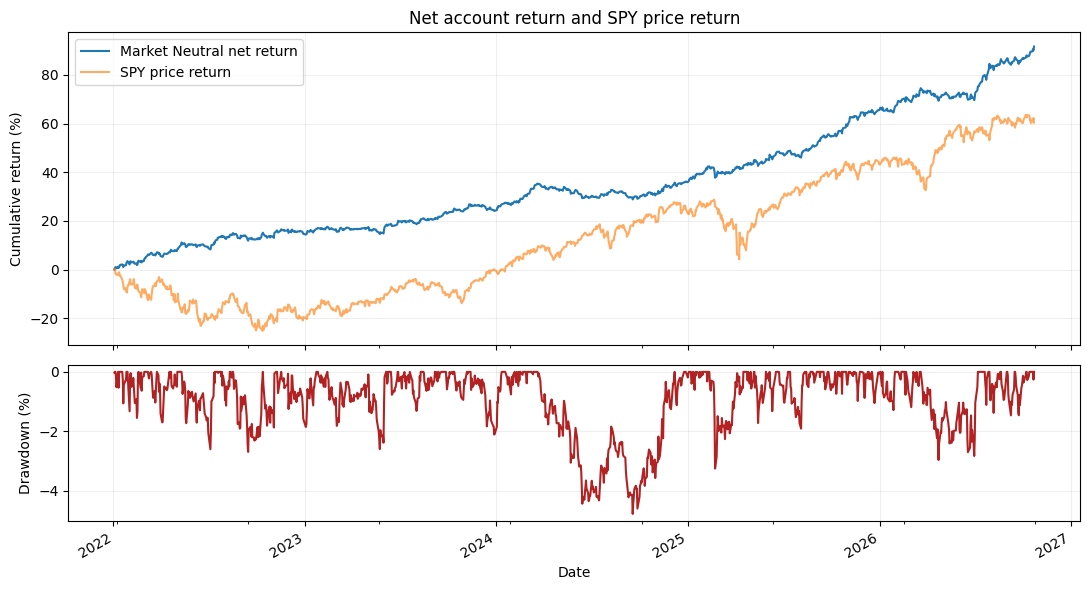

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
daily.cumulative_return.mul(100).plot(ax=axes[0], label="Market Neutral net return")
daily.spy_cumulative_return.mul(100).plot(ax=axes[0], label="SPY price return", alpha=.65)
axes[0].set(ylabel="Cumulative return (%)", title="Net account return and SPY price return")
axes[0].legend()
(daily.equity / daily.equity.cummax().clip(lower=parameters["backtest"]["initial_nav"]) - 1).mul(100).plot(ax=axes[1], color="firebrick")
axes[1].set(ylabel="Drawdown (%)", xlabel="Date")
plt.tight_layout()
plt.show()

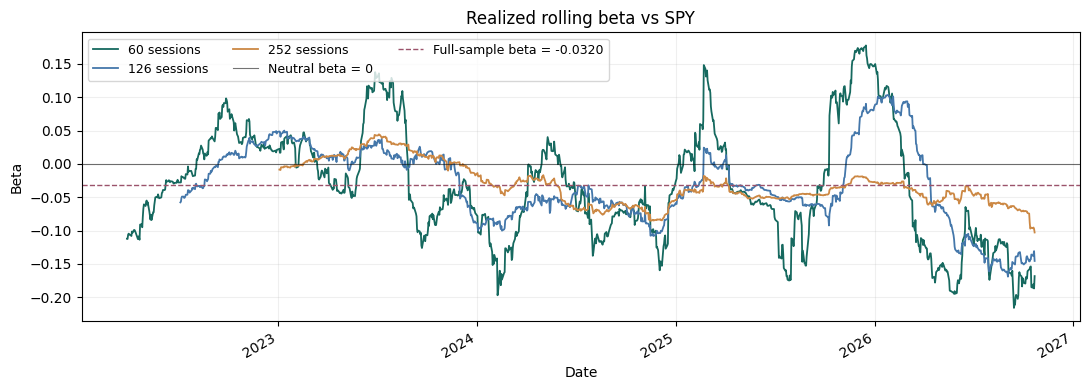

As of 2026-10-22 | Full-sample beta: -0.0320


,Latest,Minimum,Maximum
Rolling window,,,
60 sessions,-0.1683,-0.2160,0.1778
126 sessions,-0.1456,-0.1691,0.1036
252 sessions,-0.1028,-0.1028,0.0444


Daily net account returns vs SPY price returns; no annualization or cumulative-return inputs.
A full window of paired observations is required; early values remain blank.
Realized rolling beta differs from the estimated beta constraint used to form target holdings.


In [6]:
from risk import BetaAnalysis

# Diagnostic windows only; these do not change portfolio construction or trades.
BETA_WINDOWS = (60, 126, 252)
beta_analysis = BetaAnalysis(daily["spy_return"].rename("SPY price return"),
                             daily["daily_return"].rename("Market Neutral net account return"))
market, strategy = beta_analysis.x, beta_analysis.y
rolling_betas = pd.DataFrame({
    f"{window} sessions": strategy.rolling(window, min_periods=window).cov(market)
        / market.rolling(window, min_periods=window).var(ddof=1).replace(0, float("nan"))
    for window in BETA_WINDOWS
})

ax = rolling_betas.plot(figsize=(11, 4), linewidth=1.3,
                       color=["#16695f", "#4477aa", "#cc8844"])
ax.axhline(0, color="black", linewidth=.8, alpha=.55, label="Neutral beta = 0")
ax.axhline(beta_analysis.beta, color="#9b536b", linestyle="--", linewidth=1,
           label=f"Full-sample beta = {beta_analysis.beta:.4f}")
ax.set(title="Realized rolling beta vs SPY", ylabel="Beta", xlabel="Date")
ax.legend(ncol=3, fontsize=9)
plt.tight_layout()
plt.show()

beta_summary = pd.DataFrame({
    "Latest": rolling_betas.iloc[-1],
    "Minimum": rolling_betas.min(),
    "Maximum": rolling_betas.max(),
})
beta_summary.index.name = "Rolling window"
print(f"As of {rolling_betas.index[-1].date()} | Full-sample beta: {beta_analysis.beta:.4f}")
display(beta_summary.style.format("{:.4f}"))
print("Daily net account returns vs SPY price returns; no annualization or cumulative-return inputs.")
print("A full window of paired observations is required; early values remain blank.")
print("Realized rolling beta differs from the estimated beta constraint used to form target holdings.")

In [7]:
checks = pd.DataFrame(result["rebalance_summary"])
print(f"Monthly decisions: {len(checks)} | Mean target names: {checks.target_longs.mean():.1f} long / {checks.target_shorts.mean():.1f} short")
print(f"Total trading cost: ${daily.cumulative_transaction_cost.iloc[-1]:,.2f} | Total borrow cost: ${daily.cumulative_borrow_fee.iloc[-1]:,.2f}")
print(f"Accounting: {result['verification']['accounting']} | Stale-price legs: {result['verification']['stale_price_legs']}")
print(f"Independent full-ledger reconstruction: {result['verification'].get('independent_parameter_reconstruction', False)}")
print("Factor union across small underlying combinations:", result["metrics"]["factors"])
print("Full model, sector filters, allocations and limits:", parameter_path.relative_to(PROJECT))

Monthly decisions: 58 | Mean target names: 41.2 long / 35.3 short
Total trading cost: $23,405.00 | Total borrow cost: $32,484.02
Accounting: passed | Stale-price legs: 0
Independent full-ledger reconstruction: True
Factor union across small underlying combinations: average_asset_roa + cashflow_yield + earnings_yield + gross_profitability + low_accruals + low_volatility + momentum + momentum_6_1 + quality + roa
Full model, sector filters, allocations and limits: result\aqr\monthly_sharpe158\parameters.py


**Configuration:** `PARAMETER_FILE=None` uses `AQRSettings.selected_parameter_file`. An explicit notebook path takes precedence. Preset execution and performance fields override method defaults; omitted fields in these two sections use defaults. The separate baseline's quarterly setting does not override the monthly preset. Editing a preset does not rewrite saved results; the parameter fingerprint catches stale results, and `RERUN=True` recomputes them.

**RF and averaging:** the annual-quote mean above describes the data. The saved Sharpe uses the mean and sample standard deviation of **daily excess returns**, after matching historical RF to each interval. It does not replace historical quotes with one fixed average. RF is a performance hurdle; no cash interest is credited to NAV. The first interval uses a one-day approximation.

**Data limitations:** member-site financial CSVs contain latest vendor versions, potentially restated. Known availability dates take priority; missing dates use period-end +90 days. This is not a verified as-filed archive. Dividends, short dividend compensation, cash interest and tax are excluded. Tax-loss harvesting is not implemented.

[Research report](report.html) | [Historical universe](aqr_research/universe.html) | [Self-contained preset](result/aqr/monthly_sharpe158/parameters.py)

**Weighting:** `weighting_method=1` applies demean/L1 to `alpha_column` directly, without model overlays; the bundled `score` column is the original three-factor baseline alpha. `weighting_method=2` runs the configured factor model and remains selected for the displayed Sharpe 1.6364. `weighting_method=3` is reserved and raises as not implemented. Both illustrative examples in the HTML share the same final normalization; only alpha preparation differs. Choice 1 does not enforce beta neutrality or the configured model's single-name cap. See the preset comments before changing the choice.